In [85]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
import numpy as np
import matplotlib.pyplot as plt

In [26]:
df= pd.read_csv('course_lead_scoring_2026.csv')

In [27]:
df.head ()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [28]:
categorical_column=list(df.dtypes[df.dtypes=='str'].index)
numerical_column=list(df.dtypes[(df.dtypes=='float64')| (df.dtypes=='int64')].index)

In [29]:
numerical_column.remove("converted")

In [30]:
numerical_column

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score']

In [31]:
df[numerical_column].isnull().sum()

annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
dtype: int64

In [32]:
df[categorical_column]=df[categorical_column].fillna(value='NA')
df[numerical_column]=df[numerical_column].fillna(value=0.0)


In [33]:
df[numerical_column].isnull().sum()

annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
dtype: int64

In [34]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [35]:
df_full_train,df_test= train_test_split(df,test_size=0.2,random_state=1)
df_train,df_val=train_test_split(df_full_train,test_size=0.25,random_state=1)

In [36]:
y_train=df_train.converted.values
for col in numerical_column:
    y_score=df_train[col]

    auc=roc_auc_score(y_train,y_score)

    if auc <0.5:
        y_score=-df_train[col]
        auc=roc_auc_score(y_train,y_score)

    print((col,auc))


('annual_income', 0.6081977776250831)
('number_of_courses_viewed', 0.7229894623989618)
('interaction_count', 0.7649203047563227)
('lead_score', 0.7882254810906102)


In [37]:

#one-hot-encoding
dv=DictVectorizer(sparse=False)
train_dicts=df_train[categorical_column + numerical_column].to_dict(orient='records')
X_train=dv.fit_transform(train_dicts)



In [38]:
#training the model 
model=LogisticRegression(solver='liblinear',C=1.0,max_iter=1000)
model.fit(X_train,y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [ ]:
#making prediction
val_dicts=df_val[categorical_column + numerical_column].to_dict(orient='records')
X_val=dv.transform(val_dicts)
y_val=df_val.converted.values
y_pred=model.predict_proba(X_val)


In [55]:
y_pred[::,1]



array([0.54472295, 0.79005191, 0.50977882, 0.52913934, 0.82072017,
       0.54245972, 0.50178712, 0.54698383, 0.82553291, 0.40583727,
       0.91301561, 0.33581811, 0.3078986 , 0.42704772, 0.62192275,
       0.53665458, 0.41931913, 0.84087339, 0.79969125, 0.61790114,
       0.61625177, 0.68059912, 0.85605897, 0.80784865, 0.62045997,
       0.45970701, 0.54556694, 0.41221371, 0.72714005, 0.46812072,
       0.77222173, 0.79043872, 0.61433884, 0.78549743, 0.49753403,
       0.66077266, 0.69804748, 0.7689654 , 0.65657485, 0.64127885,
       0.66509096, 0.57942799, 0.67830929, 0.61186087, 0.86890227,
       0.41469665, 0.84130122, 0.74229349, 0.68028533, 0.71891426,
       0.86417924, 0.64043347, 0.54246978, 0.70225148, 0.27894882,
       0.70826471, 0.62310687, 0.47781739, 0.37914002, 0.69936026,
       0.52032849, 0.69977687, 0.75148933, 0.58087478, 0.47001782,
       0.56863462, 0.91297177, 0.79972016, 0.82206537, 0.36140182,
       0.66132377, 0.52330037, 0.79295454, 0.72068061, 0.71234

In [58]:
auc_val=roc_auc_score(y_val,y_pred[::,1])
print(auc_val)

0.7318222288173319


In [63]:
threshold=np.linspace(0.0,1.0,101)
threshold

array([0.  , 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1 ,
       0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2 , 0.21,
       0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3 , 0.31, 0.32,
       0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.4 , 0.41, 0.42, 0.43,
       0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.5 , 0.51, 0.52, 0.53, 0.54,
       0.55, 0.56, 0.57, 0.58, 0.59, 0.6 , 0.61, 0.62, 0.63, 0.64, 0.65,
       0.66, 0.67, 0.68, 0.69, 0.7 , 0.71, 0.72, 0.73, 0.74, 0.75, 0.76,
       0.77, 0.78, 0.79, 0.8 , 0.81, 0.82, 0.83, 0.84, 0.85, 0.86, 0.87,
       0.88, 0.89, 0.9 , 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98,
       0.99, 1.  ])

In [102]:
actual_positive=(y_val==1)
actual_negative=(y_val==0)
y_pred_prob=y_pred[:,1]

score=[]

for t in threshold:
    predict_positive= (y_pred_prob >=t)
    predict_negative=(y_pred_prob <t)
    tp=(predict_positive & actual_positive).sum()
    tn=(predict_negative & actual_negative).sum()
    fn=(predict_negative & actual_positive).sum()
    fp=(predict_positive & actual_negative).sum()
    if tp+fp==0:
        precision=0
        recall=0
        F_1_score=0
    else:
        precision=tp/(tp+fp)
        recall=tp/(tp+fn)
        F_1_score=2*(precision*recall)/(precision+recall)
    
    score.append((t,precision,recall,F_1_score))


In [103]:
df_scores = pd.DataFrame(score, columns=['threshold', 'precision', 'recall','F1_score'])


In [104]:
df_scores

,threshold,precision,recall,F1_score
0,0.00,0.586,1.000000,0.738966
1,0.01,0.586,1.000000,0.738966
2,0.02,0.586,1.000000,0.738966
3,0.03,0.586,1.000000,0.738966
4,0.04,0.586,1.000000,0.738966
...,...,...,...,...
96,0.96,1.000,0.001706,0.003407
97,0.97,0.000,0.000000,0.000000
98,0.98,0.000,0.000000,0.000000
99,0.99,0.000,0.000000,0.000000


In [105]:
df_scores_final=df_scores.copy()
df_scores_final=df_scores[:97]

In [111]:
#intersection of the curves
ecart=(df_scores_final['precision']-df_scores_final['recall']).abs()
small_ecart=ecart.min()
index=ecart.idxmin()
t_inter=df_scores_final.loc[index,'threshold']

In [115]:
#threshold for macium F_1_score
index_f_1_max=df_scores_final.F1_score.idxmax()
threshold_f1=df_scores_final.loc[index_f_1_max,'threshold']
threshold_f1

np.float64(0.41000000000000003)

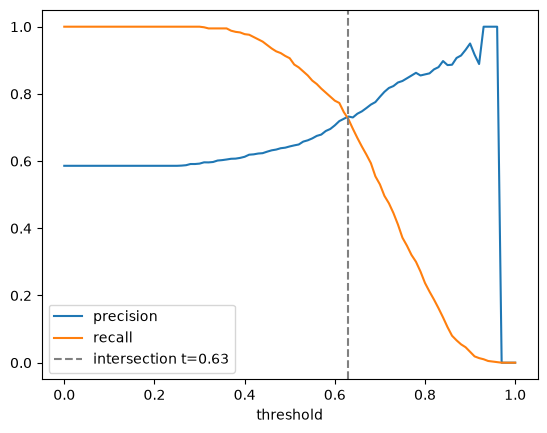

In [100]:
plt.plot(df_scores.threshold,df_scores.precision,label='precision')
plt.plot(df_scores.threshold,df_scores.recall,label='recall')
plt.xlabel('threshold')

plt.axvline(x=t_inter, linestyle='--', color='grey', label=f'intersection t={t_inter:.2f}')
plt.legend()
plt.show()
